<h1 style="font-size: 1.6rem; font-weight: bold">ITO 5136: Software Engineering</h1>
<h1 style="font-size: 1.6rem; font-weight: bold">Module 2: Requirements Engineering</h1>
<p style="margin-top: 5px; margin-bottom: 5px;">Monash University Australia</p>
<p style="margin-top: 5px; margin-bottom: 5px;">Jupyter Notebook by: Tristan Sim Yook Min</p>
References: Information Source from Monash Faculty of Information Technology

---

### **1. Requirements Engineering**

#### Good requirements are
- **Specific** – describe one unambiguous behaviour, not "user-friendly" or "fast".
- **Testable** – you can write a test (or a command) that proves the requirement is met.
- **User-focused** – describe what the user needs, not how to implement it.
- **Complete** – acceptance criteria leave no gaps about when the work is "done".
- **Traceable** – every requirement can be followed to the stories, tests, commits and merge requests that satisfy it.

#### User stories
- Template: **"As a [user], I want to [action] so that [benefit]."** The benefit clause forces you to justify why the feature exists.
- One story per feature; small enough to complete in one or two days, otherwise split it.
- Bad: "Fix the login stuff." Good: "As a registered user, I want to reset my password by email so that I can regain access to my account."

#### Acceptance criteria
- Written as Given/When/Then or a checklist: *given input X, the system outputs Y with exit code 0*.
- Vague criteria ("it works") earn passing grades; traceable criteria demonstrate engineering rigour and become the test cases later.
- Include the error and edge cases, not only the happy path (what happens with invalid input, missing data, insufficient stock?).

#### Handling ambiguity
- Real specifications are never complete. The professional response is: identify the ambiguity, form a reasonable interpretation, state it, and confirm with the stakeholder – "propose-then-confirm" keeps work moving while waiting for an answer.
- Document every clarification where the affected requirement lives, so decisions are traceable to their source.
- Reuse existing clarifications (read what others asked) instead of duplicating questions.
- When an answer contradicts a written requirement, update the requirement immediately: requirements are living documents.

#### Planning
- **Milestones** are time-boxed goals with start and due dates; name them by goal ("MVP core shopping flow"), not by number.
- MVP first: the first milestone should produce a working end-to-end product; enhancements and quality work come after.
- **Labels** (feature / enhancement / bug / chore) make the backlog filterable and reveal the balance of work.
- **Weights** (1 trivial → 8 large) estimate effort; anything rated 8+ is a signal to split.
- **Burndown charts** show remaining work against an ideal line: above the line = behind schedule, flat = blocked, sudden drops = batching instead of continuous delivery.
- Document **constraints** (things you cannot change: mandated technology, fixed deadlines, team size) and **trade-offs** (choices between competing qualities, with the reasoning) in a permanent decision record. A decision that is not written down will be re-litigated later.

***

### **2. Git fundamentals**

#### Commits
- Commit small, logical slices; each commit should be reviewable and revertable on its own.
- **Conventional commit messages:** `type: subject` where type ∈ feat, fix, chore, refactor, test, docs, ci. Subject under ~72 chars, imperative; blank line; body explaining *why*, not just what.
- A log of "fix stuff" and "update" is useless in review and impossible to search; the tag costs one word.
- Never commit: virtual environments, caches/bytecode, secrets (.env), build artefacts. Write the `.gitignore` before creating any of them.
- Do commit: lockfiles (`uv.lock`) and version pins (`.python-version`) – they make every clone reproduce the same environment.

#### Branches
- `main` is protected: no direct pushes, no force pushes, changes arrive only through reviewed merge requests. This preserves an audit trail and keeps broken code off the shared branch.
- Feature work happens on short-lived, descriptively named branches: `feat/user-login`, `fix/parse-csv`. Branch from up-to-date `main`; delete the branch after merge.
- One feature (or fix) per branch = one per merge request: focused scope reviews faster and reverts cleaner.

#### Pre-commit hooks
- Automated checks that run before every commit (whitespace, end-of-file, syntax, large files). If a hook modifies files, the commit aborts – stage the fix and commit again. Quality gates this early are cheaper than review comments or CI failures.

***

### **4. Merge request practice**

#### What makes a good merge request
- **Focused scope:** one feature or fix, not everything at once.
- **Self-explaining description:** What was done / Why / How to test / which issue it closes (`Closes #N` auto-closes on merge). A reviewer should know what to look for without asking.
- **Evidence of thought:** comments on non-obvious decisions in the code.
- **Tests included:** the author has run them and they pass.

#### The cycle
branch → build & test → commit in slices → push → open MR (draft while incomplete) → request review → respond to every comment (change it, or explain the disagreement) → approve → merge (delete source branch) → pull main → verify linked issues closed.

#### Review etiquette
- Draft status signals "not ready for judgement"; mark Ready only when description and code are complete.
- Respond to all review comments – silence is neither agreement nor rebuttal.
- Merging without any review defeats the purpose even where self-approval is technically allowed; the review is where defects and design smells get caught cheapest.

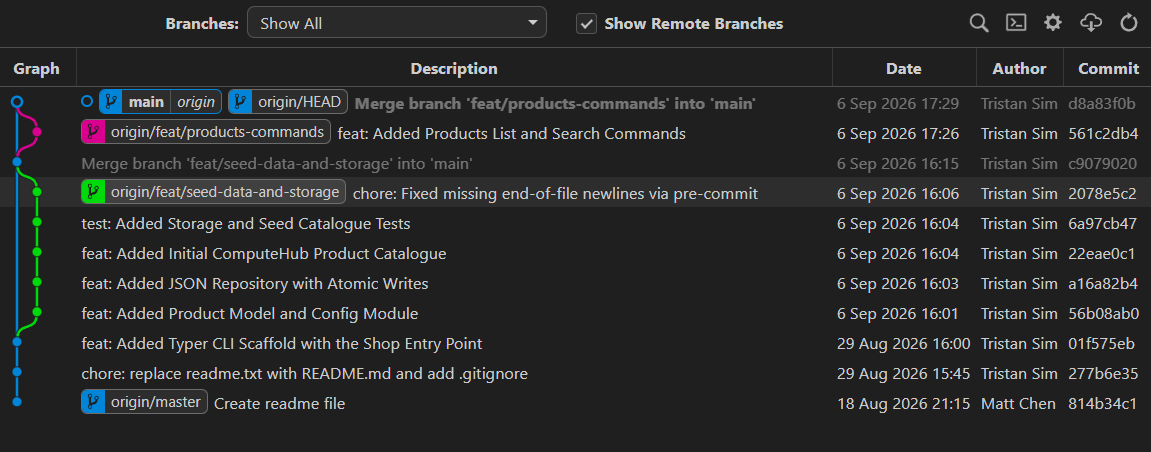

***

### **5. Testing principles (previewed; assessed fully later)**

- Minimum three cases per function: **happy path, edge case, error case.**
- Tests must be **independent and deterministic**: no shared state, no reliance on run order, no touching real data files (use fixtures and temporary directories).
- Test names describe the behaviour under test (`test_load_corrupted_file_raises_storage_error`), so a failure reads as a sentence.
- Each test should have a single reason to fail.
- Techniques: **equivalence partitioning** (one representative per class of input) and **boundary value analysis** (test at and around the limits).
- Tests catch integration mistakes cheaply – a wrong filename, a broken import – before a reviewer or marker does.

### **6. Meta-practices**

- **Traceability end-to-end:** requirement → story → acceptance criteria → tests → commits → merge request → closed issue. Anyone can follow the chain in either direction.
- **Evidence as you go:** screenshots and logs captured at the moment of configuration are cheap; reconstructing them later is not.
- **Decisions in writing:** constraints, trade-offs and clarifications live in a decision record, each with its reasoning and source.
- **Small errors are errors:** typos, inconsistent naming and stale references count against "no identifiable errors" – proofread everything a reviewer will see.
- **Verify, don't assume:** settings drift, files get renamed, commits get aborted by hooks. `git status` and a refreshed settings page beat confidence.